In [ ]:
!pip install -q pandas numpy scikit-learn underthesea rank-bm25 sentence-transformers openpyxl tqdm

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import time
import re

uploaded = files.upload()

print("Các file đã tải lên:", list(uploaded.keys()))

Saving questions_template.csv to questions_template.csv
Saving chunks (1).csv to chunks (1).csv
Các file đã tải lên: ['questions_template.csv', 'chunks (1).csv']


In [ ]:
chunks = pd.read_csv(
    "chunks (1).csv",
    encoding="utf-8-sig"
)

questions = pd.read_csv(
    "questions_template.csv",
    encoding="utf-8-sig"
)

print("Số chunks:", len(chunks))
print("Số câu hỏi:", len(questions))

display(chunks.head())
display(questions.head())

Số chunks: 1061
Số câu hỏi: 20


,document_id,page,chunk_id,text
0,dlbookvn_chap05.pdf,1,dlbookvn_chap05.pdf_P1_C1,Chương 5 Machine Learning cơ bản 5.1 Learning ...
1,dlbookvn_chap05.pdf,2,dlbookvn_chap05.pdf_P2_C1,5.10 Xây dựng một thuật toán ML 5.11 Những thá...
2,dlbookvn_chap05.pdf,2,dlbookvn_chap05.pdf_P2_C2,sẽ mô tả các thách thức trong việc tạo ra mô h...
3,dlbookvn_chap05.pdf,2,dlbookvn_chap05.pdf_P2_C3,tả hai cách học này và đưa ra một vài ví dụ đơ...
4,dlbookvn_chap05.pdf,3,dlbookvn_chap05.pdf_P3_C1,góp phần thúc đẩy sự phát triển các thuật toán...


,query_id,question,gold_chunk_ids
0,Q001,Thuật toán ML hoạt động tốt nhất khi nào?,dlbookvn_chap05.pdf_P19_C1
1,Q002,Độ chinhs xác là gì ?,dlbookvn_chap05.pdf_P8_C2
2,Q003,Các thuật toán học có giám sát là gì?,dlbookvn_chap05.pdf_P49_C1
3,Q004,Thuật toán phân cụm K- Means hoạt động như thế...,dlbookvn_chap05.pdf_P60_C1
4,Q005,Vấn đề mà ML thường gặp phải là gì,dlbookvn_chap05.pdf_P61_C3


In [ ]:
import unicodedata
import re

# Kiểm tra các cột bắt buộc
required_columns = [
    "document_id",
    "page",
    "chunk_id",
    "text"
]

for col in required_columns:
    if col not in chunks.columns:
        raise ValueError(f"Thiếu cột {col} trong chunks.csv")

# Loại dòng không có nội dung
chunks = chunks.dropna(subset=["text"]).copy()

# Tạo cột văn bản phục vụ truy xuất
def prepare_text(text):
    text = str(text)

    # Chuẩn hóa Unicode NFC
    text = unicodedata.normalize("NFC", text)

    # Chuẩn hóa khoảng trắng, không tự sửa từ dính
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n+", " ", text)

    return text.strip()

chunks["text_processed"] = chunks["text"].apply(prepare_text)

# Đồng bộ hóa chunk_key bằng chính chunk_id gốc để trùng với gold_chunk_ids
chunks["chunk_key"] = chunks["chunk_id"].astype(str).str.strip()

# Kiểm tra
print("Tổng số chunks:", len(chunks))
print("Số chunk ID trùng:", chunks["chunk_key"].duplicated().sum())

display(
    chunks[
        ["document_id", "page", "chunk_id",
         "chunk_key", "text_processed"]
    ].head()
)

Tổng số chunks: 1061
Số chunk ID trùng: 0


,document_id,page,chunk_id,chunk_key,text_processed
0,dlbookvn_chap05.pdf,1,dlbookvn_chap05.pdf_P1_C1,dlbookvn_chap05.pdf_P1_C1,Chương 5 Machine Learning cơ bản 5.1 Learning ...
1,dlbookvn_chap05.pdf,2,dlbookvn_chap05.pdf_P2_C1,dlbookvn_chap05.pdf_P2_C1,5.10 Xây dựng một thuật toán ML 5.11 Những thá...
2,dlbookvn_chap05.pdf,2,dlbookvn_chap05.pdf_P2_C2,dlbookvn_chap05.pdf_P2_C2,sẽ mô tả các thách thức trong việc tạo ra mô h...
3,dlbookvn_chap05.pdf,2,dlbookvn_chap05.pdf_P2_C3,dlbookvn_chap05.pdf_P2_C3,tả hai cách học này và đưa ra một vài ví dụ đơ...
4,dlbookvn_chap05.pdf,3,dlbookvn_chap05.pdf_P3_C1,dlbookvn_chap05.pdf_P3_C1,góp phần thúc đẩy sự phát triển các thuật toán...


In [ ]:
required_question_columns = [
    "query_id",
    "question",
    "gold_chunk_ids"
]

for col in required_question_columns:
    if col not in questions.columns:
        raise ValueError(f"Thiếu cột {col} trong questions_template.csv")

# Chuyển nội dung về dạng chuỗi
questions["question"] = (
    questions["question"].fillna("").astype(str).str.strip()
)

questions["gold_chunk_ids"] = (
    questions["gold_chunk_ids"].fillna("").astype(str).str.strip()
)

# Loại các dòng chưa có câu hỏi
questions = questions[
    questions["question"] != ""
].copy()

print("Số câu hỏi đã điền:", len(questions))
display(questions.head(10))

Số câu hỏi đã điền: 20


,query_id,question,gold_chunk_ids
0,Q001,Thuật toán ML hoạt động tốt nhất khi nào?,dlbookvn_chap05.pdf_P19_C1
1,Q002,Độ chinhs xác là gì ?,dlbookvn_chap05.pdf_P8_C2
2,Q003,Các thuật toán học có giám sát là gì?,dlbookvn_chap05.pdf_P49_C1
3,Q004,Thuật toán phân cụm K- Means hoạt động như thế...,dlbookvn_chap05.pdf_P60_C1
4,Q005,Vấn đề mà ML thường gặp phải là gì,dlbookvn_chap05.pdf_P61_C3
5,Q006,Xử lý ngôn ngữ tự nhiên là gì?,tom tat kien thuc tong quan NLP.pdf_P1_C1
6,Q007,Quá triình phân tích hình thái trong xử lý ngô...,tom tat kien thuc tong quan NLP.pdf_P1_C2
7,Q008,Tính mơ hồ của ngôn ngữ là gì?,tom tat kien thuc tong quan NLP.pdf_P3_C1
8,Q009,Ngữ pháp là?,tom tat kien thuc tong quan NLP.pdf_P4_C1
9,Q010,Nhận dạng thực thể có tên là gì?,tom tat kien thuc tong quan NLP.pdf_P9_C2


kiểm tra id đáp án chuẩn

In [ ]:
def parse_gold_ids(value):
    if pd.isna(value) or str(value).strip() == "":
        return set()

    return {
        x.strip()
        for x in str(value).split(";")
        if x.strip()
    }


questions["gold_ids"] = (
    questions["gold_chunk_ids"].apply(parse_gold_ids)
)

all_chunk_ids = set(chunks["chunk_id"])

check_data = []

for _, row in questions.iterrows():

    gold_ids = row["gold_ids"]
    missing = gold_ids - all_chunk_ids

    if len(gold_ids) == 0:
        status = "Chưa gắn đáp án chuẩn"
    elif len(missing) > 0:
        status = "ID không tồn tại"
    else:
        status = "Hợp lệ"

    check_data.append({
        "query_id": row["query_id"],
        "question": row["question"],
        "gold_count": len(gold_ids),
        "missing_ids": "; ".join(missing),
        "status": status
    })

check_df = pd.DataFrame(check_data)

display(check_df)

print("\nThống kê:")
print(check_df["status"].value_counts())

,query_id,question,gold_count,missing_ids,status
0,Q001,Thuật toán ML hoạt động tốt nhất khi nào?,1,,Hợp lệ
1,Q002,Độ chinhs xác là gì ?,1,,Hợp lệ
2,Q003,Các thuật toán học có giám sát là gì?,1,,Hợp lệ
3,Q004,Thuật toán phân cụm K- Means hoạt động như thế...,1,,Hợp lệ
4,Q005,Vấn đề mà ML thường gặp phải là gì,1,,Hợp lệ
5,Q006,Xử lý ngôn ngữ tự nhiên là gì?,1,,Hợp lệ
6,Q007,Quá triình phân tích hình thái trong xử lý ngô...,1,,Hợp lệ
7,Q008,Tính mơ hồ của ngôn ngữ là gì?,1,,Hợp lệ
8,Q009,Ngữ pháp là?,1,,Hợp lệ
9,Q010,Nhận dạng thực thể có tên là gì?,1,,Hợp lệ



Thống kê:
status
Hợp lệ    20
Name: count, dtype: int64


chuâne bị dữ liệu


In [ ]:
from underthesea import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer
from tqdm.auto import tqdm

corpus = chunks["text_processed"].tolist()

chunk_ids = chunks["chunk_key"].tolist()

# Hàm tách từ tiếng Việt
def tokenize_vi(text):
    result = word_tokenize(str(text), format="text")

    return [
        token.lower().strip()
        for token in result.split()
        if token.strip()
    ]

print("Số chunks:", len(corpus))
print("Thử tách từ:")
print(tokenize_vi(corpus[0])[:30])

Số chunks: 1061
Thử tách từ:
['chương', '5', 'machine', 'learning_cơ_bản', '5.1', 'learning_algorithms_5.1.1', 'tác_vụ', '5.1.2', 'đánh_giá', 'hiệu_năng', '5.1.3_kinh_nghiệm', '5.1.4', 'ví_dụ', ':', 'hồi', 'quy_tuyến', 'tính', '5.2_capacity', ',', 'over', '\uf001_tting', 'và', 'under', '\uf001_tting', '5.3_siêu', 'tham_số', 'và', 'tập', 'xác', 'thực_5.3.1']


Mô hình 1 – TF-IDF + Cosine Similarity

In [ ]:
tfidf_vectorizer = TfidfVectorizer(
    tokenizer=tokenize_vi,
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 2),
    min_df=1,
    max_features=100000
)

tfidf_matrix = tfidf_vectorizer.fit_transform(corpus)

print("Kích thước ma trận TF-IDF:", tfidf_matrix.shape)

Kích thước ma trận TF-IDF: (1061, 82912)


In [ ]:
# hàm truy xuất
def retrieve_tfidf(query, top_k=5):

    start = time.perf_counter()

    query_vector = tfidf_vectorizer.transform([query])

    scores = cosine_similarity(
        query_vector,
        tfidf_matrix
    ).flatten()

    top_indices = np.argsort(scores)[::-1][:top_k]

    elapsed = time.perf_counter() - start

    results = []

    for idx in top_indices:
        results.append({
            "chunk_id": chunk_ids[idx],
            "score": float(scores[idx]),
            "text": corpus[idx]
        })

    return results, elapsed

bm35

In [ ]:
tokenized_corpus = [
    tokenize_vi(text)
    for text in tqdm(corpus, desc="Tokenize BM25")
]

bm25 = BM25Okapi(tokenized_corpus)

print("Đã xây dựng chỉ mục BM25!")

Tokenize BM25:   0%|          | 0/1061 [00:00<?, ?it/s]

Đã xây dựng chỉ mục BM25!


In [ ]:
def retrieve_bm25(query, top_k=5):

    start = time.perf_counter()

    query_tokens = tokenize_vi(query)

    scores = bm25.get_scores(query_tokens)

    top_indices = np.argsort(scores)[::-1][:top_k]

    elapsed = time.perf_counter() - start

    results = []

    for idx in top_indices:
        results.append({
            "chunk_id": chunk_ids[idx],
            "score": float(scores[idx]),
            "text": corpus[idx]
        })

    return results, elapsed

Mô hình 3 – Embedding + Cosine Similarity

In [ ]:
embedding_model = SentenceTransformer(
    "intfloat/multilingual-e5-small"
)

print("Đã tải mô hình Embedding!")

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Đã tải mô hình Embedding!


In [ ]:
passage_texts = [
    "passage: " + text
    for text in corpus
]

document_embeddings = embedding_model.encode(
    passage_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Kích thước ma trận Embedding:", document_embeddings.shape)

Batches:   0%|          | 0/34 [00:00<?, ?it/s]

Kích thước ma trận Embedding: (1061, 384)


In [ ]:
def retrieve_embedding(query, top_k=5):

    start = time.perf_counter()

    query_embedding = embedding_model.encode(
        ["query: " + query],
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    scores = np.dot(
        document_embeddings,
        query_embedding[0]
    )

    top_indices = np.argsort(scores)[::-1][:top_k]

    elapsed = time.perf_counter() - start

    results = []

    for idx in top_indices:
        results.append({
            "chunk_id": chunk_ids[idx],
            "score": float(scores[idx]),
            "text": corpus[idx]
        })

    return results, elapsed

In [ ]:
retrievers = {
    "TF-IDF": retrieve_tfidf,
    "BM25": retrieve_bm25,
    "Embedding": retrieve_embedding
}

test_question = questions.iloc[0]["question"]

print("CÂU HỎI:", test_question)

for method, func in retrievers.items():

    results, elapsed = func(test_question, top_k=5)

    print("\n" + "=" * 70)
    print("PHƯƠNG PHÁP:", method)
    print("Thời gian:", round(elapsed, 4), "giây")

    for rank, item in enumerate(results, 1):

        print(
            f"\nTop {rank} | "
            f"ID: {item['chunk_id']} | "
            f"Score: {item['score']:.4f}"
        )

        print(item["text"][:500])

CÂU HỎI: Thuật toán ML hoạt động tốt nhất khi nào?

PHƯƠNG PHÁP: TF-IDF
Thời gian: 0.0489 giây

Top 1 | ID: dlbookvn_chap05.pdf_P25_C1 | Score: 0.1682
từng được quan sát. Nói cách khác, theo một nghĩa nào đó, không có thuật toán ML nào luôn luôn tốt hơn hơn các thuật toán ML còn lại. Thuật toán phức tạp nhất ta có thể hình dung có cùng một hiệu suất trung bình (trên tất cả các tác vụ có thể) giống như các thuật toán chỉ đơn thuần dự đoán mọi điểm dữ liệu thuộc về cùng một lớp. May mắn thay, những kết quả này chỉ đúng khi ta lấy trung bình trên toàn bộ các phân phối sinh dữ liệu . Nếu ta đưa ra những giả định về các loại phân phối xác suất mà t

Top 2 | ID: dlbookvn_chap05.pdf_P25_C2 | Score: 0.1471
mà một tác nhân AI trải nghiệm, và các loại thuật toán ML nào hoạt động tốt trên dữ liệu được lấy ra từ các loại phân phối sinh dữ liệu mà ta quan tâm. 5.2.2 Cơ chế kiểm soát Luật bù trừ ngụ ý rằng ta phải thiết kế các thuật toán ML có thể hoạt động tốt trên một tác vụ cụ thể. Ta sẽ thực hiệ

In [ ]:
#chạy thực nghiệm trên toàn bộ câu hỏi

In [ ]:
def evaluate_retrieval(retrieved_ids, gold_ids, k=5):

    if len(gold_ids) == 0:
        return None

    top_ids = retrieved_ids[:k]

    relevant_count = len(set(top_ids) & gold_ids)

    precision = relevant_count / len(top_ids) if top_ids else 0

    recall = relevant_count / len(gold_ids)

    reciprocal_rank = 0

    for rank, chunk_id in enumerate(top_ids, start=1):
        if chunk_id in gold_ids:
            reciprocal_rank = 1 / rank
            break

    return {
        "Precision@5": precision,
        "Recall@5": recall,
        "MRR": reciprocal_rank
    }

chạy đánh giá

In [ ]:
TOP_K = 5

valid_questions = questions[
    questions["gold_ids"].apply(
        lambda x: len(x) > 0 and x.issubset(all_chunk_ids)
    )
].copy()

print("Số câu hỏi hợp lệ:", len(valid_questions))

if len(valid_questions) == 0:
    raise ValueError(
        "Chưa có câu hỏi nào được gắn gold_chunk_ids hợp lệ. "
        "Hãy hoàn thiện đáp án chuẩn trước."
    )

evaluation_results = []
retrieval_details = []

for _, row in tqdm(
    valid_questions.iterrows(),
    total=len(valid_questions),
    desc="Đang đánh giá"
):

    query_id = row["query_id"]
    question = row["question"]
    gold_ids = row["gold_ids"]

    for method, func in retrievers.items():

        results, elapsed = func(
            question,
            top_k=TOP_K
        )

        retrieved_ids = [
            item["chunk_id"]
            for item in results
        ]

        metrics = evaluate_retrieval(
            retrieved_ids,
            gold_ids,
            k=TOP_K
        )

        evaluation_results.append({
            "query_id": query_id,
            "method": method,
            **metrics,
            "latency_seconds": elapsed
        })

        for rank, item in enumerate(results, 1):

            retrieval_details.append({
                "query_id": query_id,
                "question": question,
                "method": method,
                "rank": rank,
                "chunk_id": item["chunk_id"],
                "score": item["score"],
                "is_relevant": item["chunk_id"] in gold_ids,
                "text": item["text"]
            })

results_df = pd.DataFrame(evaluation_results)

details_df = pd.DataFrame(retrieval_details)

print("Đã hoàn thành đánh giá!")

Số câu hỏi hợp lệ: 20


Đang đánh giá:   0%|          | 0/20 [00:00<?, ?it/s]

Đã hoàn thành đánh giá!


In [ ]:
# tổng hợp kết quả
summary = (
    results_df
    .groupby("method")
    .agg({
        "Precision@5": "mean",
        "Recall@5": "mean",
        "MRR": "mean",
        "latency_seconds": "mean"
    })
    .reset_index()
)

summary = summary.round(4)

summary

,method,Precision@5,Recall@5,MRR,latency_seconds
0,BM25,0.15,0.75,0.5417,0.0053
1,Embedding,0.11,0.55,0.4000,0.0417
2,TF-IDF,0.14,0.70,0.6100,0.0120


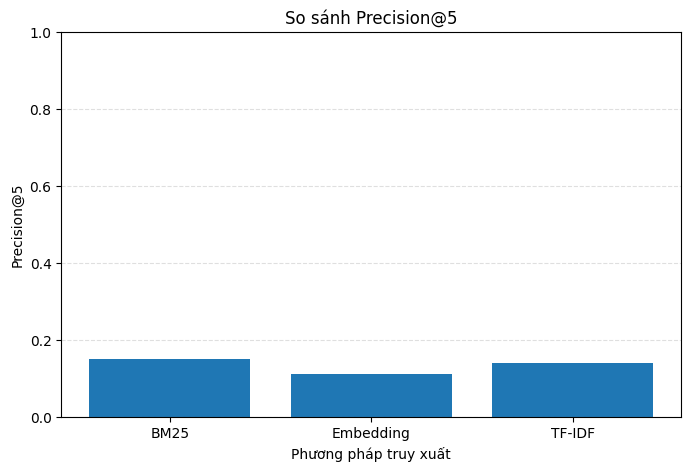

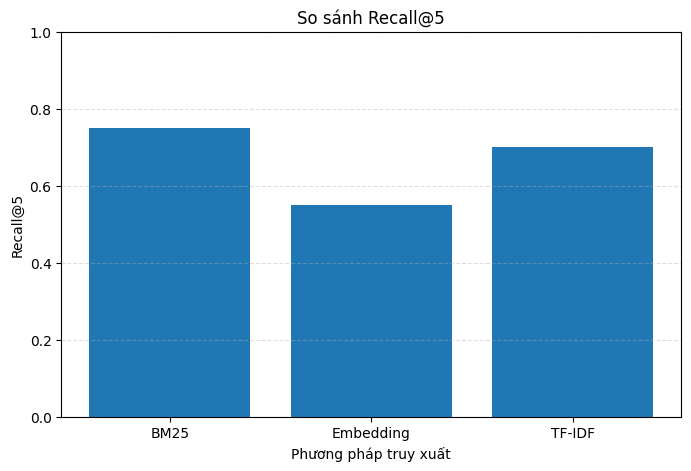

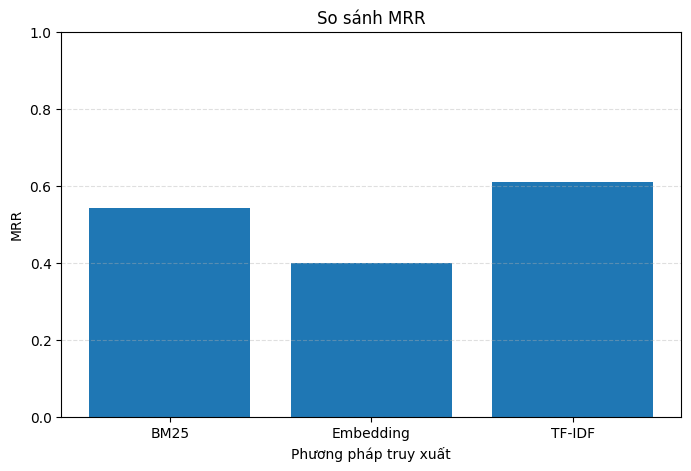

In [ ]:
import matplotlib.pyplot as plt

for metric in ["Precision@5", "Recall@5", "MRR"]:

    plt.figure(figsize=(8, 5))

    plt.bar(
        summary["method"],
        summary[metric]
    )

    plt.title(f"So sánh {metric}")
    plt.xlabel("Phương pháp truy xuất")
    plt.ylabel(metric)
    plt.ylim(0, 1)
    plt.grid(axis="y", linestyle="--", alpha=0.4)

    plt.show()

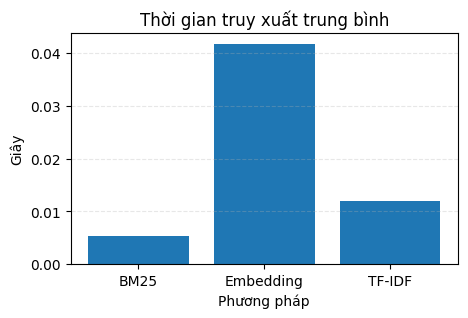

In [ ]:
plt.figure(figsize=(5, 3))

plt.bar(
    summary["method"],
    summary["latency_seconds"]
)

plt.title("Thời gian truy xuất trung bình")
plt.xlabel("Phương pháp")
plt.ylabel("Giây")

plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.show()

In [ ]:
import re
import pandas as pd
from google.colab import files

output_file = "ket_qua_thuc_nghiem_RAG.xlsx"

# Hàm loại bỏ các ký tự không hợp lệ trong file Excel (Illegal XML characters)
def clean_illegal_chars(val):
    if isinstance(val, str):
        # Loại bỏ các ký tự điều khiển không hợp lệ
        # Giữ lại các ký tự hợp lệ thông thường
        return re.sub(r'[\x00-\x08\x0b\x0c\x0e-\x1f\xff\xfe\uf000-\uf002]', '', val)
    return val

# Áp dụng làm sạch cho tất cả các DataFrame trước khi ghi ra file Excel
summary_cleaned = summary.applymap(clean_illegal_chars) if hasattr(pd, 'applymap') else summary.map(clean_illegal_chars)
results_df_cleaned = results_df.applymap(clean_illegal_chars) if hasattr(pd, 'applymap') else results_df.map(clean_illegal_chars)
details_df_cleaned = details_df.applymap(clean_illegal_chars) if hasattr(pd, 'applymap') else details_df.map(clean_illegal_chars)
check_df_cleaned = check_df.applymap(clean_illegal_chars) if hasattr(pd, 'applymap') else check_df.map(clean_illegal_chars)

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    summary_cleaned.to_excel(
        writer,
        sheet_name="Tong_hop",
        index=False
    )

    results_df_cleaned.to_excel(
        writer,
        sheet_name="Chi_tiet_danh_gia",
        index=False
    )

    details_df_cleaned.to_excel(
        writer,
        sheet_name="Ket_qua_truy_xuat",
        index=False
    )

    check_df_cleaned.to_excel(
        writer,
        sheet_name="Kiem_tra_cau_hoi",
        index=False
    )

files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Thiết lập đánh giá cấp độ Câu (Sentence-Level Evaluation)
Bước này sẽ chuyển đổi `gold_chunk_ids` thành nội dung văn bản chuẩn thực tế (`gold_texts`) bằng cách tra cứu nội dung text tương ứng trong tập dữ liệu `chunks`.

In [ ]:
import pandas as pd
import numpy as np

# Khởi tạo từ điển tra cứu nhanh nội dung text từ chunk_key
chunk_text_map = dict(zip(chunks["chunk_key"], chunks["text_processed"]))

def get_gold_texts(gold_ids_set):
    # Lấy văn bản thực tế của các gold chunks làm tiêu chuẩn đối chiếu câu
    texts = []
    for cid in gold_ids_set:
        if cid in chunk_text_map:
            texts.append(chunk_text_map[cid])
    return texts

# Tạo cột chứa nội dung đáp án mẫu dạng văn bản
questions["gold_texts"] = questions["gold_ids"].apply(get_gold_texts)

# Kiểm tra cấu trúc câu hỏi mới kèm text chuẩn
display(questions[["query_id", "question", "gold_texts"]].head())

,query_id,question,gold_texts
0,Q001,Thuật toán ML hoạt động tốt nhất khi nào?,[tiếp tục bổ sung các luỹ thừa bậc cao hơn của...
1,Q002,Độ chinhs xác là gì ?,[5.1.2 Đánh giá hiệu năng Để đánh giá khả năng...
2,Q003,Các thuật toán học có giám sát là gì?,[5.7 Các thuật toán học có giám sát Như đã đượ...
3,Q004,Thuật toán phân cụm K- Means hoạt động như thế...,[5.8.2 Phân cụm -means Một ví dụ đơn giản khác...
4,Q005,Vấn đề mà ML thường gặp phải là gì,[quan trọng: stochastic gradient descent (SGD)...


### Định nghĩa lại Hàm Đánh Giá cấp độ Câu (Sentence-Level Metric)
Hàm này kiểm tra xem trong danh sách các chunk được tìm thấy, có chunk nào chứa bất kỳ câu văn bản chuẩn nào trong `gold_texts` hay không.

In [ ]:
def evaluate_retrieval_sentence_level(retrieved_chunks, gold_texts, k=5):
    """
    Đánh giá độ chính xác tìm kiếm dựa trên nội dung chứa văn bản đáp án chuẩn.
    retrieved_chunks: Danh sách dict chứa thông tin chunk gồm có trường 'text'
    gold_texts: Danh sách các chuỗi văn bản đáp án chuẩn
    """
    if not gold_texts:
        return None

    top_chunks = retrieved_chunks[:k]
    relevant_indices = []

    # Kiểm tra từng chunk được trả về
    for rank_idx, chunk in enumerate(top_chunks):
        chunk_text = prepare_text(chunk.get("text", ""))
        is_relevant = False

        # Một chunk được coi là đúng nếu nó chứa bất kỳ đáp án chuẩn nào
        for gold in gold_texts:
            if gold in chunk_text or chunk_text in gold:
                is_relevant = True
                break

        if is_relevant:
            relevant_indices.append(rank_idx)

    relevant_count = len(relevant_indices)
    precision = relevant_count / len(top_chunks) if top_chunks else 0
    # Ở cấp độ câu, Recall là tỷ lệ câu trả lời chuẩn tìm thấy
    recall = 1.0 if relevant_count > 0 else 0.0

    reciprocal_rank = 0
    if relevant_indices:
        first_match_rank = relevant_indices[0] + 1
        reciprocal_rank = 1 / first_match_rank

    return {
        "Precision@5": precision,
        "Recall@5": recall,
        "MRR": reciprocal_rank
    }


In [ ]:
# Tiến hành chạy thử nghiệm đánh giá cấp độ Câu trên toàn bộ tập dữ liệu
eval_results_sentence = []
detail_results_sentence = []

for _, row in tqdm(valid_questions.iterrows(), total=len(valid_questions), desc="Đánh giá cấp độ Câu"):
    query_id = row["query_id"]
    question = row["question"]
    gold_texts = get_gold_texts(row["gold_ids"])

    for method, func in retrievers.items():
        results, elapsed = func(question, top_k=TOP_K)

        metrics = evaluate_retrieval_sentence_level(results, gold_texts, k=TOP_K)

        eval_results_sentence.append({
            "query_id": query_id,
            "method": method,
            **metrics,
            "latency_seconds": elapsed
        })

        for rank, item in enumerate(results, 1):
            is_relevant = False
            for g_txt in gold_texts:
                if g_txt in prepare_text(item["text"]) or prepare_text(item["text"]) in g_txt:
                    is_relevant = True
                    break

            detail_results_sentence.append({
                "query_id": query_id,
                "question": question,
                "method": method,
                "rank": rank,
                "chunk_id": item["chunk_id"],
                "score": item["score"],
                "is_relevant": is_relevant,
                "text": item["text"]
            })

results_sentence_df = pd.DataFrame(eval_results_sentence)
details_sentence_df = pd.DataFrame(detail_results_sentence)

# Tổng hợp kết quả mới
summary_sentence = (
    results_sentence_df
    .groupby("method")
    .agg({
        "Precision@5": "mean",
        "Recall@5": "mean",
        "MRR": "mean",
        "latency_seconds": "mean"
    })
    .reset_index()
)

display(summary_sentence.round(4))
# độ đo recall@k : đánh giá đáp án đúng có xuất hiện trong top k hay khôg?( k xét thứ tự )
#MRR : đáp án đúng ở vị trí nào?


Đánh giá cấp độ Câu:   0%|          | 0/20 [00:00<?, ?it/s]

,method,Precision@5,Recall@5,MRR,latency_seconds
0,BM25,0.15,0.75,0.5417,0.0049
1,Embedding,0.11,0.55,0.4000,0.0392
2,TF-IDF,0.14,0.70,0.6100,0.0114


Lấy nội dung truy xuất top 5 của các mô hình

In [ ]:
def get_retrieved_chunks(retrieved_ids, chunks_df):

    # Tạo bảng tra cứu ID -> nội dung
    chunk_lookup = chunks_df.set_index("chunk_id")["text"]

    # Lấy nội dung theo đúng thứ tự ID truy xuất
    retrieved_chunks = []

    for chunk_id in retrieved_ids:
        if chunk_id in chunk_lookup.index:
            retrieved_chunks.append({
                "chunk_id": chunk_id,
                "text": chunk_lookup.loc[chunk_id]
            })

    return retrieved_chunks

In [ ]:
# Lấy thử danh sách ID được truy xuất từ kết quả kiểm tra trước đó (ví dụ lấy từ câu hỏi đầu tiên)
# Nếu bạn đã có sẵn biến retrieved_ids từ trước, bạn có thể bỏ dòng gán này.
if 'retrieved_ids' not in globals():
    retrieved_ids = list(questions.iloc[0]["gold_ids"])

# Sử dụng đúng tên biến bảng dữ liệu là 'chunks'
retrieved_chunks = get_retrieved_chunks(
    retrieved_ids,
    chunks
)

for chunk in retrieved_chunks:
    print("ID:", chunk["chunk_id"])
    print("Nội dung:", chunk["text"])
    print("-" * 50)

ID: tom tat kien thuc tong quan NLP.pdf_P8_C1
Nội dung: 4.2.2. Khử mơ hồ nghĩa từ (Word Sense Disambiguation - WSD) WSD là quá trình xác định nghĩa chính xác của một từ đa nghĩa trong một ngữ cảnh cụ thể. Đây là một nhiệm vụ quan trọng vì nó ảnh hưởng đến độ chính xác của các ứng dụng NLP khác như dịch máy, tìm kiếm thông tin và phân tích cảm xúc. Các phương pháp WSD bao gồm: Dựa trên từ điển (Dictionary-based): Sử dụng các tài nguyên từ vựng như WordNet để tìm kiếm các định nghĩa và mối quan hệ giữa các từ. Dựa trên ngữ liệu (Corpus-based): Sử dụng các mô hình học máy được huấn luyện trên các ngữ liệu lớn để học cách phân biệt các nghĩa của từ dựa trên ngữ cảnh xung quanh [5]. 4.2.3. Biểu diễn ý nghĩa từ (Word Embeddings) Word embeddings là các biểu diễn vector dày đặc của từ trong một không gian đa chiều, trong đó các từ có ý nghĩa tương tự sẽ có vị trí gần nhau. Các mô hình word embedding phổ biến bao gồm Word2Vec, GloVe và FastText. Chúng giúp máy tính nắm bắt được mối quan hệ ngữ 

tạo ngữ cảnh bằng cách nối các đoạn churk thành chuỗi văn bản

In [ ]:
def build_context(retrieved_chunks):

    context = ""

    for i, chunk in enumerate(retrieved_chunks, start=1):

        context += f"""
        [Đoạn văn bản {i}]
        {chunk['text']}
        """

    return context

In [ ]:
context = build_context(retrieved_chunks)

print(context)


        [Đoạn văn bản 1]
        4.2.2. Khử mơ hồ nghĩa từ (Word Sense Disambiguation - WSD) WSD là quá trình xác định nghĩa chính xác của một từ đa nghĩa trong một ngữ cảnh cụ thể. Đây là một nhiệm vụ quan trọng vì nó ảnh hưởng đến độ chính xác của các ứng dụng NLP khác như dịch máy, tìm kiếm thông tin và phân tích cảm xúc. Các phương pháp WSD bao gồm: Dựa trên từ điển (Dictionary-based): Sử dụng các tài nguyên từ vựng như WordNet để tìm kiếm các định nghĩa và mối quan hệ giữa các từ. Dựa trên ngữ liệu (Corpus-based): Sử dụng các mô hình học máy được huấn luyện trên các ngữ liệu lớn để học cách phân biệt các nghĩa của từ dựa trên ngữ cảnh xung quanh [5]. 4.2.3. Biểu diễn ý nghĩa từ (Word Embeddings) Word embeddings là các biểu diễn vector dày đặc của từ trong một không gian đa chiều, trong đó các từ có ý nghĩa tương tự sẽ có vị trí gần nhau. Các mô hình word embedding phổ biến bao gồm Word2Vec, GloVe và FastText. Chúng giúp máy tính nắm bắt được mối quan hệ ngữ nghĩa giữa các từ một 

lưu kết quả truy xuất thành file csv

In [ ]:
import pandas as pd

retrieval_results = []

In [ ]:
#hàm lưu kết quả top 5
def save_retrieval_result(
    query_id,
    question,
    method,
    retrieved_ids,
    scores,
    chunks_df
):
    # Tra cứu nội dung đoạn văn bản bằng chunk_id
    chunk_lookup = chunks_df.set_index("chunk_id")["text"]

    for rank, (chunk_id, score) in enumerate(
        zip(retrieved_ids[:5], scores[:5]),
        start=1
    ):

        # Kiểm tra ID có tồn tại trong dữ liệu gốc không
        if chunk_id not in chunk_lookup.index:
            continue

        retrieval_results.append({
            "query_id": query_id,
            "question": question,
            "method": method,
            "chunk_id": chunk_id,
            "rank": rank,
            "score": float(score),
            "text": chunk_lookup.loc[chunk_id]
        })

In [ ]:
for _, row in questions.iterrows():

    query_id = row["query_id"]
    question = row["question"]

    # 1. TF-IDF
    tfidf_ids, tfidf_scores = retrieve_tfidf(
        question, top_k=5
    )

    # Chuyển đổi cấu trúc kết quả TF-IDF để lấy danh sách id và score riêng biệt
    tfidf_id_list = [item["chunk_id"] for item in tfidf_ids]
    tfidf_score_list = [item["score"] for item in tfidf_ids]

    save_retrieval_result(
        query_id, question, "TF-IDF",
        tfidf_id_list, tfidf_score_list, chunks
    )

    # 2. BM25
    bm25_ids, bm25_scores = retrieve_bm25(
        question, top_k=5
    )

    bm25_id_list = [item["chunk_id"] for item in bm25_ids]
    bm25_score_list = [item["score"] for item in bm25_ids]

    save_retrieval_result(
        query_id, question, "BM25",
        bm25_id_list, bm25_score_list, chunks
    )

    # 3. Embedding
    embedding_ids, embedding_scores = retrieve_embedding(
        question, top_k=5
    )

    embedding_id_list = [item["chunk_id"] for item in embedding_ids]
    embedding_score_list = [item["score"] for item in embedding_ids]

    save_retrieval_result(
        query_id, question, "Embedding",
        embedding_id_list, embedding_score_list, chunks
    )

In [ ]:
# Chuyển danh sách thành DataFrame
retrieval_df = pd.DataFrame(retrieval_results)

# Sắp xếp kết quả
retrieval_df = retrieval_df.sort_values(
    by=["query_id", "method", "rank"]
)

# Lưu thành CSV
retrieval_df.to_csv(
    "retrieval_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu kết quả truy xuất!")
print("Số dòng:", len(retrieval_df))

display(retrieval_df.head(10))

Đã lưu kết quả truy xuất!
Số dòng: 300


,query_id,question,method,chunk_id,rank,score,text
5,Q001,Thuật toán ML hoạt động tốt nhất khi nào?,BM25,dlbookvn_chap05.pdf_P25_C1,1,21.920890,"từng được quan sát. Nói cách khác, theo một ng..."
6,Q001,Thuật toán ML hoạt động tốt nhất khi nào?,BM25,dlbookvn_chap05.pdf_P25_C2,2,18.650490,"mà một tác nhân AI trải nghiệm, và các loại th..."
7,Q001,Thuật toán ML hoạt động tốt nhất khi nào?,BM25,dlbookvn_chap05.pdf_P16_C2,3,17.221880,"hơn. 5.2 Capacity, Overtting, Undertting Thá..."
8,Q001,Thuật toán ML hoạt động tốt nhất khi nào?,BM25,dlbookvn_chap05.pdf_P16_C1,4,17.143265,Chúng tôi sẽ thường xuyên sử dụng thuật ngữ “t...
9,Q001,Thuật toán ML hoạt động tốt nhất khi nào?,BM25,dlbookvn_chap05.pdf_P27_C3,5,14.568117,nào ta thực hiện cho thuật toán học tập nhằm g...
10,Q001,Thuật toán ML hoạt động tốt nhất khi nào?,Embedding,dlbookvn_chap05.pdf_P25_C2,1,0.879117,"mà một tác nhân AI trải nghiệm, và các loại th..."
11,Q001,Thuật toán ML hoạt động tốt nhất khi nào?,Embedding,dlbookvn_chap05.pdf_P9_C2,2,0.864946,nó thỉnh thoảng mắc những lỗi rất lớn? Những l...
12,Q001,Thuật toán ML hoạt động tốt nhất khi nào?,Embedding,dlbookvn_chap05.pdf_P25_C1,3,0.864935,"từng được quan sát. Nói cách khác, theo một ng..."
13,Q001,Thuật toán ML hoạt động tốt nhất khi nào?,Embedding,dlbookvn_chap05.pdf_P20_C2,4,0.862900,này còn được gọi là dung lượng biểu diễn (repr...
14,Q001,Thuật toán ML hoạt động tốt nhất khi nào?,Embedding,dlbookvn_chap05.pdf_P8_C3,5,0.862564,lỗi hoặc các loại mất mát 0-1 thường không có ...


In [ ]:
from google.colab import files

files.download("retrieval_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>